# Notebook 01 – Dataset Audit and Exploratory Data Analysis

Check the FatigueData-AM2022 workbook, compare its counts with the dataset paper and explore the S-N data before modelling.

**Dataset:** Zhang, Z. & Xu, Z., *Fatigue database of additively manufactured alloys*, Scientific Data 10, 249 (2023). Figshare DOI 10.6084/m9.figshare.22337629 (version 2, CC BY 4.0).

## 1. Setup and file integrity

Import the libraries and project helper functions, and create the output folders.

In [1]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Make the project's src/ folder importable from the notebooks/ folder.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import data_utils as du
import feature_utils as fu
from evaluation_utils import set_plot_style, save_figure, PALETTE

set_plot_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

AUDIT_DIR = PROJECT_ROOT / "results" / "audit"
FIG_DIR = PROJECT_ROOT / "results" / "figures"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)

Python 3.13.5 | pandas 3.1.1 | numpy 2.5.5


Check that the raw workbook and JSON file are the original Figshare files (SHA-256 and MD5 checksums).

In [2]:
RAW_FILES = ["FatigueData-AM2022.xlsx", "FatigueData-AM2022.json"]
raw_paths = {name: du.ensure_raw_data(name) for name in RAW_FILES}       # downloads only what is missing; MD5 checked
workbook_path = raw_paths["FatigueData-AM2022.xlsx"]

record_existed = du.PROVENANCE_PATH.exists()
provenance = du.ensure_provenance_record(RAW_FILES)                     # created only if absent, never overwritten
print("Provenance record:", "existing record from the original download" if record_existed
      else "rebuilt now from the Figshare API record and the files on disk")
for name in RAW_FILES:
    entry = provenance["files_downloaded"][name]
    assert du.sha256_of_file(raw_paths[name]) == entry["sha256_on_disk"], f"{name} differs from the provenance record."
    assert du.md5_of_file(raw_paths[name]) == entry["md5_reported_by_figshare"], f"{name} does not match the MD5 published by Figshare."
print("Both raw files match the provenance record (SHA-256) and the MD5 published by Figshare.\n")

record = provenance["files_downloaded"]["FatigueData-AM2022.xlsx"]
sha256_now = du.sha256_of_file(workbook_path)

print("File            :", workbook_path.relative_to(PROJECT_ROOT))
print("Size on disk    :", f"{workbook_path.stat().st_size:,} bytes  (Figshare lists {record['size_bytes_reported_by_figshare']:,})")
print("SHA-256 now     :", sha256_now)
print("SHA-256 recorded:", record["sha256_on_disk"])
print("Unchanged since download:", sha256_now == record["sha256_on_disk"])
print("MD5 matches Figshare    :", du.md5_of_file(workbook_path) == record["md5_reported_by_figshare"])
print("Source          :", record["download_url"], "| DOI", provenance["dataset_doi"], "| version", provenance["figshare_version"])
print("Licence         :", provenance["license"]["name"], "| downloaded (UTC):", provenance["download_date_utc"],
      f"({provenance.get('download_date_source', 'recorded at download')})")
assert sha256_now == record["sha256_on_disk"], "The raw workbook differs from the provenance record."

Provenance record: existing record from the original download


Both raw files match the provenance record (SHA-256) and the MD5 published by Figshare.

File            : data\raw\FatigueData-AM2022.xlsx
Size on disk    : 7,044,408 bytes  (Figshare lists 7,044,408)
SHA-256 now     : 95c0c41266f32a275bcef834bfd7674079861a2d00d3974e5e6fd0ad7100528b
SHA-256 recorded: 95c0c41266f32a275bcef834bfd7674079861a2d00d3974e5e6fd0ad7100528b
Unchanged since download: True
MD5 matches Figshare    : True
Source          : https://ndownloader.figshare.com/files/41023484 | DOI 10.6084/m9.figshare.22337629.v2 | version 2
Licence         : CC BY 4.0 | downloaded (UTC): 2026-11-19T21:23:36+00:00 (recorded at download)


## 2. Loading the workbook

Load the four sheets and rename the long workbook headers to short column names. The `parameter` sheet has two header rows, so the second row is used as the header.

In [3]:
sheet_names = pd.ExcelFile(workbook_path, engine="openpyxl").sheet_names
print("Sheets found in the workbook:", sheet_names)

raw_headers = {}
frames = {}
column_maps = {}
for sheet in sheet_names:
    raw = du.load_sheet_raw(sheet, workbook_path)
    raw_headers[sheet] = list(raw.columns)
    frames[sheet], column_maps[sheet] = du.rename_columns(raw)

sn = frames[du.SHEET_SN]
en = frames[du.SHEET_EN]
dadn = frames[du.SHEET_DADN]
param = frames[du.SHEET_PARAM]

summary = du.sheet_summary(frames)
summary.to_csv(AUDIT_DIR / "sheet_summary.csv", index=False)
summary

Sheets found in the workbook: ['S-N', 'e-N', 'dadn', 'parameter']


,sheet,rows,columns,fully_duplicated_rows
0,S-N,15146,4,38
1,e-N,1840,4,7
2,dadn,178061,3,994
3,parameter,2460,47,0


Show how each original workbook header maps to its project column name.

In [4]:
# The group header row of the parameter sheet (first row), read without interpretation.
group_row = pd.read_excel(workbook_path, sheet_name=du.SHEET_PARAM, header=None, nrows=1, engine="openpyxl").iloc[0]
print("Parameter sheet, first header row (column groups):", [g for g in group_row.dropna().tolist()])

mapping_rows = []
for sheet, mapping in column_maps.items():
    for original, new in mapping.items():
        mapping_rows.append({"sheet": sheet, "workbook header": original.replace("\r\n", " ⏎ ").replace("\n", " ⏎ "), "project name": new})
column_mapping = pd.DataFrame(mapping_rows)
column_mapping.to_csv(AUDIT_DIR / "column_name_mapping.csv", index=False, encoding="utf-8-sig")
with pd.option_context("display.max_rows", 80):
    display(column_mapping)

Parameter sheet, first header row (column groups): ['metadata', 'fatigue', 'materials', 'AM', 'processing', 'testing', 'static mechanical properties', 'rating score']


,sheet,workbook header,project name
0,S-N,dataset id,dataset_id
1,S-N,life ⏎ N (cycle),N
2,S-N,stress amplitude ⏎ σa (MPa),stress_amplitude
3,S-N,runout,runout
4,e-N,dataset id,dataset_id
5,e-N,life ⏎ N (cycle),N
6,e-N,strain amplitude ⏎ εa (mm/mm),strain_amplitude
7,e-N,runout,runout
8,dadn,dataset id,dataset_id
9,dadn,stress intensity factor range ⏎ ΔK (MPa*m^(1/2)),delta_k


## 3. Column audit of each sheet

For every column, list the data type, filled cells, percentage missing, number of distinct values and an example.

In [5]:
audit_tables = {}
for sheet, frame in frames.items():
    table = du.sheet_audit_table(frame)
    audit_tables[sheet] = table
    table.to_csv(AUDIT_DIR / f"sheet_audit_{sheet.replace('-', '')}.csv", index=False, encoding="utf-8-sig")

for sheet in (du.SHEET_SN, du.SHEET_EN, du.SHEET_DADN):
    print(f"Sheet '{sheet}': {frames[sheet].shape[0]:,} rows x {frames[sheet].shape[1]} columns")
    display(audit_tables[sheet])

Sheet 'S-N': 15,146 rows x 4 columns


,column,dtype,non_null,missing_pct,n_unique,example
0,dataset_id,int64,15146,0.0,1610,1
1,N,float64,15146,0.0,14889,20047.798627110165
2,stress_amplitude,float64,15146,0.0,13899,233.96526529844243
3,runout,int64,15146,0.0,2,0


Sheet 'e-N': 1,840 rows x 4 columns


,column,dtype,non_null,missing_pct,n_unique,example
0,dataset_id,int64,1840,0.0,236,1611
1,N,float64,1840,0.0,1827,38293.56836875185
2,strain_amplitude,float64,1840,0.0,1665,0.002998755784324587
3,runout,int64,1840,0.0,2,0


Sheet 'dadn': 178,061 rows x 3 columns


,column,dtype,non_null,missing_pct,n_unique,example
0,dataset_id,int64,178061,0.0,614,1847
1,delta_k,float64,178061,0.0,53877,3.893057582359734
2,dadn,float64,178061,0.0,49624,5.309419994508138e-10


In [6]:
print(f"Sheet 'parameter': {param.shape[0]:,} rows x {param.shape[1]} columns (one row per fatigue dataset, all three data types)")
with pd.option_context("display.max_rows", 60):
    display(audit_tables[du.SHEET_PARAM])

Sheet 'parameter': 2,460 rows x 47 columns (one row per fatigue dataset, all three data types)


,column,dtype,non_null,missing_pct,n_unique,example
0,dataset_id,int64,2460,0.00,2460,1
1,title,str,2460,0.00,618,Improving the Defect Tolerance of PBF-LB/M Processed 316...
2,authors,str,2460,0.00,580,"Becker, Louis; Boes, Johannes; Cui, Chengsong; Fechte-He..."
3,journal,str,2460,0.00,113,ADVANCED ENGINEERING MATERIALS
4,year,int64,2460,0.00,17,2022
5,institution,str,2460,0.00,477,Leibniz Inst; Ruhr Univ Bochum; Tech Univ Dortmund
6,country,str,2460,0.00,129,Germany
7,funding,str,1918,22.03,303,German Research Foundation (DFG); Projekt DEAL
8,doi,str,2460,0.00,618,10.1002/adem.202200751
9,fatigue_data_type,str,2460,0.00,3,sn


*Note:* `R`, frequency and build direction are stored as text because some cells hold two values (lower and upper bound). Notebook 02 parses them.

## 4. Checks on the S-N sheet

Each row is one specimen: stress amplitude and cycles to failure (or to a run-out). Check value ranges, invalid values, duplicates and the run-out flag.

In [7]:
sn_checks = du.sn_sheet_checks(sn)
du.save_json(sn_checks, AUDIT_DIR / "sn_sheet_checks.json")
pd.Series(sn_checks, name="value").to_frame()

,value
rows,15146
unique_dataset_ids,1610
runout_value_counts,"{'0': 13295, '1': 1851}"
runout_count,1851
runout_share_pct,12.22
stress_amplitude_min,5.760575
stress_amplitude_max,1591.682267
N_min,9.710731
N_max,8496146909.796507
count_sa_le_0,0


### 4.1 Run-out flag coding

Confirm from the data that `runout = 1` means the test was stopped before failure. Run-outs should have longer lives, cluster at round limits (10⁶, 10⁷ …) and sit at the lowest stresses of their curve.

In [8]:
flag_summary = sn.assign(log_N=np.log10(sn["N"])).groupby("runout")["log_N"].describe()[["count", "min", "25%", "50%", "75%", "max"]]
print("log10(N) by flag value:")
display(flag_summary.round(2))

# Sign 2: share of points whose life is within 3% of a round number 1, 2, 3, 5 x 10^k (k >= 5).
round_lives = np.array([m * 10.0 ** k for k in range(5, 11) for m in (1, 2, 3, 5)])
def near_round(n):
    return bool(np.any(np.abs(n - round_lives) / round_lives <= 0.03))
share_round = sn.groupby("runout")["N"].apply(lambda s: s.map(near_round).mean())
print("Share of points with life within 3% of a round limit (1, 2, 3, 5 x 10^k, k>=5):")
print(share_round.round(3).to_string())

# Sign 3: in curves that contain both failures and flagged points, where do the flagged points sit?
both = sn.groupby("dataset_id")["runout"].transform(lambda s: s.nunique() == 2)
mixed = sn[both].copy()
median_failure_stress = mixed[mixed["runout"] == 0].groupby("dataset_id")["stress_amplitude"].median()
flagged = mixed[mixed["runout"] == 1]
below = (flagged["stress_amplitude"].to_numpy() <= median_failure_stress.loc[flagged["dataset_id"]].to_numpy()).mean()
print(f"\nCurves holding both flag values: {mixed['dataset_id'].nunique():,}")
print(f"Flag=1 points at or below their curve's median failure stress: {100 * below:.1f}%")

runout_confirmed = bool((flag_summary.loc[1, "50%"] > flag_summary.loc[0, "50%"]) and (share_round.loc[1] > 3 * share_round.loc[0]) and (below > 0.8))
print("\nRun-out coding (1 = run-out, 0 = failure) confirmed by all three signs:", runout_confirmed)
assert runout_confirmed, "Run-out coding could not be confirmed. Stop and ask (contingency table, section I)."

log10(N) by flag value:


,count,min,25%,50%,75%,max
runout,,,,,,
0,13295.0,0.99,4.73,5.24,5.85,9.93
1,1851.0,5.20,6.44,7.00,7.00,9.48


Share of points with life within 3% of a round limit (1, 2, 3, 5 x 10^k, k>=5):


runout
0    0.079
1    0.753



Curves holding both flag values: 930
Flag=1 points at or below their curve's median failure stress: 97.4%

Run-out coding (1 = run-out, 0 = failure) confirmed by all three signs: True


## 5. Linking the S-N sheet to the parameter sheet

Check that `dataset_id` is unique in the parameter sheet and that every S-N row finds its metadata after the join.

In [9]:
join_report = du.join_check(sn, param)

ids = {name: set(frames[name]["dataset_id"].unique()) for name in (du.SHEET_SN, du.SHEET_EN, du.SHEET_DADN)}
param_ids = set(param["dataset_id"])
in_a_data_sheet = ids[du.SHEET_SN] | ids[du.SHEET_EN] | ids[du.SHEET_DADN]
join_report["parameter_ids_not_in_any_data_sheet"] = sorted(int(i) for i in param_ids - in_a_data_sheet)
join_report["ids_shared_between_data_sheets"] = len((ids[du.SHEET_SN] & ids[du.SHEET_EN]) | (ids[du.SHEET_SN] & ids[du.SHEET_DADN]) | (ids[du.SHEET_EN] & ids[du.SHEET_DADN]))
du.save_json(join_report, AUDIT_DIR / "join_check.json")

for key, value in join_report.items():
    print(f"{key:45s}: {value}")

# Does the 'types of fatigue data' label agree with the sheet each id appears in?
type_by_sheet = {du.SHEET_SN: "sn", du.SHEET_EN: "en", du.SHEET_DADN: "dadn"}
for sheet, label in type_by_sheet.items():
    labelled = set(param.loc[param["fatigue_data_type"] == label, "dataset_id"])
    print(f"ids in sheet '{sheet}' == ids labelled '{label}' in parameter: {labelled == ids[sheet]}  ({len(ids[sheet]):,} datasets)")

joined = du.join_sn_to_parameter(sn, param)
print(f"\nS-N rows before join: {len(sn):,} | after join: {len(joined):,} | matched: {int(joined['_matched'].sum()):,}")
assert len(joined) == len(sn) and joined["_matched"].all()

key_unique_in_parameter                      : True
parameter_rows                               : 2460
parameter_rows_type_sn                       : 1610
sn_unique_ids                                : 1610
sn_ids_not_in_parameter                      : []
parameter_sn_ids_without_sn_rows             : []
parameter_ids_not_in_any_data_sheet          : []
ids_shared_between_data_sheets               : 0
ids in sheet 'S-N' == ids labelled 'sn' in parameter: True  (1,610 datasets)
ids in sheet 'e-N' == ids labelled 'en' in parameter: True  (236 datasets)
ids in sheet 'dadn' == ids labelled 'dadn' in parameter: True  (614 datasets)

S-N rows before join: 15,146 | after join: 15,146 | matched: 15,146


## 6. Articles, curves and points

Build `article_id` from the DOI and count datasets and articles for each data type. `article_id` is used only for grouping, never as a model input.

In [10]:
print("Missing DOI cells  :", int(param["doi"].isna().sum()), "| missing title cells:", int(param["title"].isna().sum()))
print("Max titles per DOI :", int(param.groupby("doi")["title"].nunique().max()), "| max DOIs per title:", int(param.groupby("title")["doi"].nunique().max()))

param["article_id"] = du.build_article_id(param)
param_sn = param[param["fatigue_data_type"] == "sn"].copy()
joined = du.join_sn_to_parameter(sn, param)

articles_by_type = param.groupby("fatigue_data_type").agg(datasets=("dataset_id", "nunique"), articles=("article_id", "nunique"))
articles_by_type.loc["all types"] = [param["dataset_id"].nunique(), param["article_id"].nunique()]
articles_by_type

Missing DOI cells  : 0 | missing title cells: 0
Max titles per DOI : 1 | max DOIs per title: 1


,datasets,articles
fatigue_data_type,,
dadn,614,135
en,236,79
sn,1610,459
all types,2460,618


Summarise and plot points per curve, curves per article and points per article.

,points per curve,curves per article,points per article
count,1610.0,459.0,459.0
mean,9.4,3.5,33.0
std,5.5,2.5,25.0
min,1.0,1.0,2.0
25%,6.0,2.0,16.0
50%,8.0,3.0,25.0
75%,12.0,4.0,45.0
max,48.0,16.0,146.0


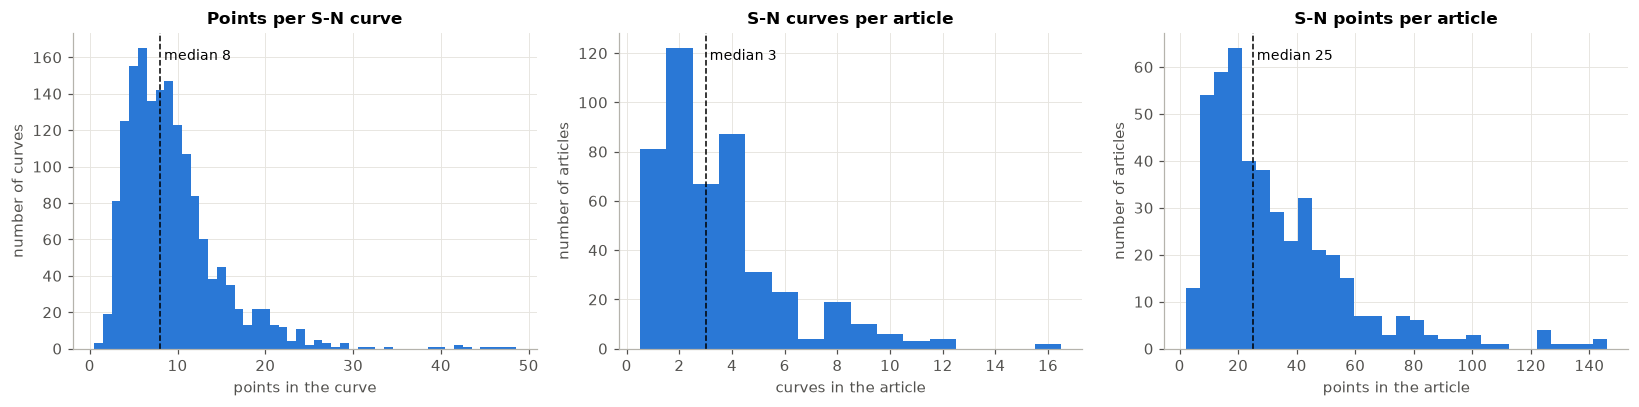

In [11]:
points_per_curve = joined.groupby("dataset_id").size()
points_per_article = joined.groupby("article_id").size()
curves_per_article = param_sn.groupby("article_id")["dataset_id"].nunique()

nesting = pd.DataFrame({
    "points per curve": points_per_curve.describe(),
    "curves per article": curves_per_article.describe(),
    "points per article": points_per_article.describe(),
}).round(1)
nesting.to_csv(AUDIT_DIR / "nesting_summary.csv")
display(nesting)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(points_per_curve, bins=np.arange(0.5, points_per_curve.max() + 1.5, 1), color=PALETTE[0])
axes[0].set(title="Points per S-N curve", xlabel="points in the curve", ylabel="number of curves")
axes[1].hist(curves_per_article, bins=np.arange(0.5, curves_per_article.max() + 1.5, 1), color=PALETTE[0])
axes[1].set(title="S-N curves per article", xlabel="curves in the article", ylabel="number of articles")
axes[2].hist(points_per_article, bins=30, color=PALETTE[0])
axes[2].set(title="S-N points per article", xlabel="points in the article", ylabel="number of articles")
for ax, series in zip(axes, (points_per_curve, curves_per_article, points_per_article)):
    ax.axvline(series.median(), color="black", lw=1, ls="--")
    ax.text(series.median(), ax.get_ylim()[1] * 0.95, f" median {series.median():.0f}", va="top", fontsize=9)
fig.tight_layout()
save_figure(fig, FIG_DIR / "01_points_curves_articles.png")
plt.show()

*Note:* the S-N points come from only a few hundred articles, so the data are nested (points within curves within articles). This is why curve- and article-held-out validation are needed.

## 7. Counted versus reported

Recount the statistics reported by the dataset authors and compare them with the values counted from the file.

In [12]:
am_share = param_sn["am_process"].value_counts(normalize=True)
param_sn["alloy_family"] = param_sn["material"].map(fu.alloy_family)
joined["alloy_family"] = joined["material"].map(fu.alloy_family)

def share_within_family(material, family):
    family_curves = param_sn[param_sn["alloy_family"] == family]
    return 100 * (family_curves["material"] == material).mean()

freq_reported_articles = param_sn.groupby("article_id")["frequency_hz"].apply(lambda s: s.notna().any()).mean()
standard_reported_articles = param_sn.groupby("article_id")["test_standard"].apply(lambda s: s.notna().any()).mean()

rows = [
    ("S-N data points", "15,146", f"{len(sn):,}"),
    ("S-N datasets (curves)", "1,610", f"{sn['dataset_id'].nunique():,}"),
    ("S-N source articles", "459", f"{param_sn['article_id'].nunique():,}"),
    ("e-N data points", "1,840", f"{len(en):,}"),
    ("e-N datasets", "236", f"{en['dataset_id'].nunique():,}"),
    ("e-N source articles", "79", f"{param.loc[param['fatigue_data_type'] == 'en', 'article_id'].nunique():,}"),
    ("da/dN datasets", "614", f"{dadn['dataset_id'].nunique():,}"),
    ("da/dN source articles", "135", f"{param.loc[param['fatigue_data_type'] == 'dadn', 'article_id'].nunique():,}"),
    ("da/dN: maximum points per dataset", "500 (subsampled)", f"{dadn.groupby('dataset_id').size().max():,}"),
    ("Distinct material names, all sheets", "116", f"{param['material'].astype(str).nunique():,}"),
    ("Distinct material names, S-N curves only", "not reported", f"{param_sn['material'].astype(str).nunique():,}"),
    ("L-PBF share of S-N curves", "83%", f"{100 * am_share.get('L-PBF', 0):.1f}%"),
    ("L-PBF share of S-N points", "83%", f"{100 * (joined['am_process'] == 'L-PBF').mean():.1f}%"),
    ("Top four AM types, share of S-N curves", "98%", f"{100 * am_share.head(4).sum():.1f}%  ({', '.join(am_share.head(4).index)})"),
    ("Datasets with rating score above 0.6 (all sheets)", "87%", f"{100 * (param['rating_score'] > 0.6).mean():.1f}%"),
    ("Datasets with rating score above 0.6 (S-N only)", "not reported", f"{100 * (param_sn['rating_score'] > 0.6).mean():.1f}%"),
    ("Ti-6Al-4V share of Ti-alloy S-N curves", "90%", f"{share_within_family('Ti-6Al-4V', 'Ti alloy'):.1f}%"),
    ("AlSi10Mg share of Al-alloy S-N curves", "66%", f"{share_within_family('AlSi10Mg', 'Al alloy'):.1f}%"),
    ("IN718 share of Ni-alloy S-N curves", "77%", f"{share_within_family('IN718', 'Ni alloy'):.1f}%"),
    ("316L share of steel S-N curves", "43%", f"{share_within_family('316L', 'Steel'):.1f}%"),
    ("S-N articles giving a test frequency", "80%", f"{100 * freq_reported_articles:.1f}%"),
    ("S-N articles giving a test standard", "40%", f"{100 * standard_reported_articles:.1f}%"),
    ("Static properties (UTS) filled, S-N curves", "50% or less", f"{100 * param_sn['uts_mpa'].notna().mean():.1f}%"),
    ("Run-out points in the S-N sheet", "not reported (open question)", f"{sn_checks['runout_count']:,} ({sn_checks['runout_share_pct']}%)"),
    ("Distinct load-ratio entries, S-N curves", "not reported (open question)", f"{param_sn['R'].astype(str).nunique()} (including empty and two-value cells)"),
]
counted_vs_reported = pd.DataFrame(rows, columns=["statistic", "reported by dataset authors", "counted from the file"])
counted_vs_reported.to_csv(AUDIT_DIR / "counted_vs_reported.csv", index=False, encoding="utf-8-sig")
with pd.option_context("display.max_colwidth", 90):
    display(counted_vs_reported)

,statistic,reported by dataset authors,counted from the file
0,S-N data points,"15,146","15,146"
1,S-N datasets (curves),"1,610","1,610"
2,S-N source articles,459,459
3,e-N data points,"1,840","1,840"
4,e-N datasets,236,236
5,e-N source articles,79,79
6,da/dN datasets,614,614
7,da/dN source articles,135,135
8,da/dN: maximum points per dataset,500 (subsampled),500
9,"Distinct material names, all sheets",116,116


*Note:* the headline counts match exactly. Small differences in the alloy shares come from our own alloy-family rule.

## 8. Key variables

Meaning of the main variables and how they are used in this project.

| Variable | Meaning | Use in the project |
|---|---|---|
| `stress_amplitude` (MPa) | Half the stress range, σa = (σmax − σmin)/2 | Input (as log10) |
| `N` (cycles) | Cycles to failure, or to the end of the test for a run-out | Target, as log10(N) |
| `runout` | 1 = test stopped before failure (true life is longer than N) | Not an input |
| `R` | Load ratio σmin/σmax (−1 = fully reversed, 0.1 = tension–tension) | Input |
| `material` | Alloy name (e.g. Ti-6Al-4V, AlSi10Mg, IN718, 316L) | Input |
| `am_process` | AM process (L-PBF, E-PBF, P-DED, W-DED, …) | Input |
| `processing` | Post-processing text: HT, HIP, NHT, SURF | Heat-treatment and surface classes (notebook 02) |
| `test_type` | Axial or bending test | Input |
| `test_temperature_c` | Test temperature | Filter (room temperature only) |
| `kt` | Stress concentration factor (1 = smooth specimen) | Optional input (tier 1) |
| `uts_mpa`, `yield_strength_mpa`, `modulus_gpa`, `elongation_pct` | Static tensile properties | Optional inputs where reported (tier 2) |
| `dataset_id` | Curve index; join key between sheets | Grouping only |
| `doi`, `title`, `authors`, `institution`, `year`, `journal` | Source article | Grouping and audit only |
| `rating_score`, `extraction_method` | Curators' score and digitising method | Audit only |

## 9. Distributions and default values

All counts in this section are per S-N curve. The dataset authors filled unreported conditions with defaults (25 °C, air, Kt = 1, force control, NHT, as-built), so these values are checked separately.

### 9.1 Main categorical columns

Count the values of AM process, test type, R, temperature, environment, load control and feedstock.

In [13]:
def value_table(series, top=None):
    counts = series.astype("object").where(series.notna(), "(empty cell)").value_counts()
    table = pd.DataFrame({"curves": counts, "share %": (100 * counts / counts.sum()).round(1)})
    return table.head(top) if top else table

distribution_columns = ["am_process", "test_type", "R", "test_temperature_c", "test_environment", "load_control", "feedstock_type"]
for column in distribution_columns:
    table = value_table(param_sn[column])
    table.to_csv(AUDIT_DIR / f"distribution_{column}.csv", encoding="utf-8-sig")
    print(f"--- {column}: {param_sn[column].nunique()} distinct values")
    print(table.to_string(), "\n")

--- am_process: 12 distinct values
                                   curves  share %
am_process                                        
L-PBF                                1301     80.8
E-PBF                                 156      9.7
P-DED                                  78      4.8
W-DED                                  55      3.4
binder jetting                          9      0.6
L-PBF + HIP                             3      0.2
metal extrusion                         2      0.1
additive friction stir deposition       2      0.1
W-DED + roll                            1      0.1
L-PBF + wrought                         1      0.1
L-PBF + laser welding                   1      0.1
bound metal deposition                  1      0.1 

--- test_type: 10 distinct values
                            curves  share %
test_type                                  
uniaxial                      1095     68.0
rotating bending fatigue       201     12.5
bending fatigue                117     

### 9.2 Alloys and alloy families

Count points, curves and articles for each alloy and alloy family.

In [14]:
alloy_table = (joined.assign(material=joined["material"].astype(str)).groupby("material")
               .agg(points=("N", "size"), curves=("dataset_id", "nunique"), articles=("article_id", "nunique"))
               .sort_values("points", ascending=False))
alloy_table["family (descriptive rule)"] = [fu.alloy_family(name) for name in alloy_table.index]
alloy_table.to_csv(AUDIT_DIR / "distribution_alloy.csv", encoding="utf-8-sig")
print(f"Distinct alloys among S-N curves: {len(alloy_table)}; alloys with fewer than 3 articles: {(alloy_table['articles'] < 3).sum()}; with a single article: {(alloy_table['articles'] == 1).sum()}")
display(alloy_table.head(15))

family_table = joined.groupby("alloy_family").agg(points=("N", "size"), curves=("dataset_id", "nunique"), articles=("article_id", "nunique")).sort_values("points", ascending=False)
display(family_table)

Distinct alloys among S-N curves: 96; alloys with fewer than 3 articles: 77; with a single article: 59


,points,curves,articles,family (descriptive rule)
material,,,,
Ti-6Al-4V,5438,553,154,Ti alloy
AlSi10Mg,1793,190,57,Al alloy
IN718,1762,187,50,Ni alloy
316L,1603,176,52,Steel
17-4 PH,515,50,17,Steel
18Ni300,413,56,12,Steel
Maraging Steel,259,26,6,Steel
IN625,199,24,8,Ni alloy
15-5 PH,162,13,3,Steel


,points,curves,articles
alloy_family,,,
Ti alloy,6058,599,172
Steel,3760,423,123
Al alloy,2700,305,85
Ni alloy,2321,248,69
Other,307,35,17


### 9.3 Heat treatment and surface

Read the free-text `processing` column and check what it says about heat treatment and surface condition.

In [15]:
# The free-text processing cell: which step types exist, and what does the cell literally say?
step_types = param_sn["processing"].map(lambda text: sorted({step.split(" ")[0] for step in fu.split_processing_steps(text)}))
print("Step type tokens found in the processing column:", sorted({t for types in step_types for t in types}))
print("Empty processing cells:", int(param_sn["processing"].isna().sum()), "of", len(param_sn), "curves\n")

ht_evidence = value_table(param_sn["processing"].map(fu.heat_treatment_evidence))
surf_evidence = value_table(param_sn["processing"].map(fu.surface_evidence))
print("What the cell says about heat treatment:"); print(ht_evidence.to_string(), "\n")
print("What the cell says about the surface:"); print(surf_evidence.to_string(), "\n")

print("Most common processing cells:")
print(value_table(param_sn["processing"], top=12).to_string())

Step type tokens found in the processing column: ['HIP', 'HT', 'NHT', 'SURF']
Empty processing cells: 27 of 1610 curves

What the cell says about heat treatment:
                                curves  share %
processing                                     
HT step                            745     46.3
no heat-treatment step in cell     361     22.4
NHT stated (may be a default)      277     17.2
HIP step                           117      7.3
HIP and HT steps                   110      6.8 

What the cell says about the surface:
                                    curves  share %
processing                                         
surface treatment stated              1115     69.3
as-built stated (may be a default)     422     26.2
no SURF step in cell                    73      4.5 

Most common processing cells:
                                                                     curves  share %
processing                                                                          


### 9.4 Share of default values

Count how many S-N curves hold the documented default value of each field.

In [16]:
# Share of S-N curves holding the documented default value, for the fields that have a default.
defaults = [
    ("test_temperature_c", 25, "test temperature 25 °C"),
    ("test_environment", "air", "test environment air"),
    ("kt", 1.0, "Kt = 1"),
    ("load_control", "force", "load control force"),
    ("preheat_temperature_c", 25, "preheat 25 °C"),
]
rows = []
for column, default, label in defaults:
    values = param_sn[column]
    rows.append({"field": label, "curves with this value": int((values == default).sum()),
                 "share of curves %": round(100 * float((values == default).mean()), 1),
                 "empty cells": int(values.isna().sum())})
rows.append({"field": "heat treatment 'NHT' stated", "curves with this value": int(ht_evidence.loc["NHT stated (may be a default)", "curves"]),
             "share of curves %": float(ht_evidence.loc["NHT stated (may be a default)", "share %"]),
             "empty cells": int(ht_evidence.loc["no heat-treatment step in cell", "curves"])})
rows.append({"field": "surface 'as-built' stated", "curves with this value": int(surf_evidence.loc["as-built stated (may be a default)", "curves"]),
             "share of curves %": float(surf_evidence.loc["as-built stated (may be a default)", "share %"]),
             "empty cells": int(surf_evidence.loc["no SURF step in cell", "curves"])})
default_share = pd.DataFrame(rows)
default_share.to_csv(AUDIT_DIR / "default_value_shares.csv", index=False, encoding="utf-8-sig")
default_share

,field,curves with this value,share of curves %,empty cells
0,test temperature 25 °C,1545,96.0,0
1,test environment air,1600,99.4,0
2,Kt = 1,1515,94.1,0
3,load control force,1427,88.6,0
4,preheat 25 °C,39,2.4,1154
5,heat treatment 'NHT' stated,277,17.2,361
6,surface 'as-built' stated,422,26.2,73


### 9.5 Category distribution plots

Plot curves per alloy, AM process, load ratio, heat treatment, surface condition and test type.

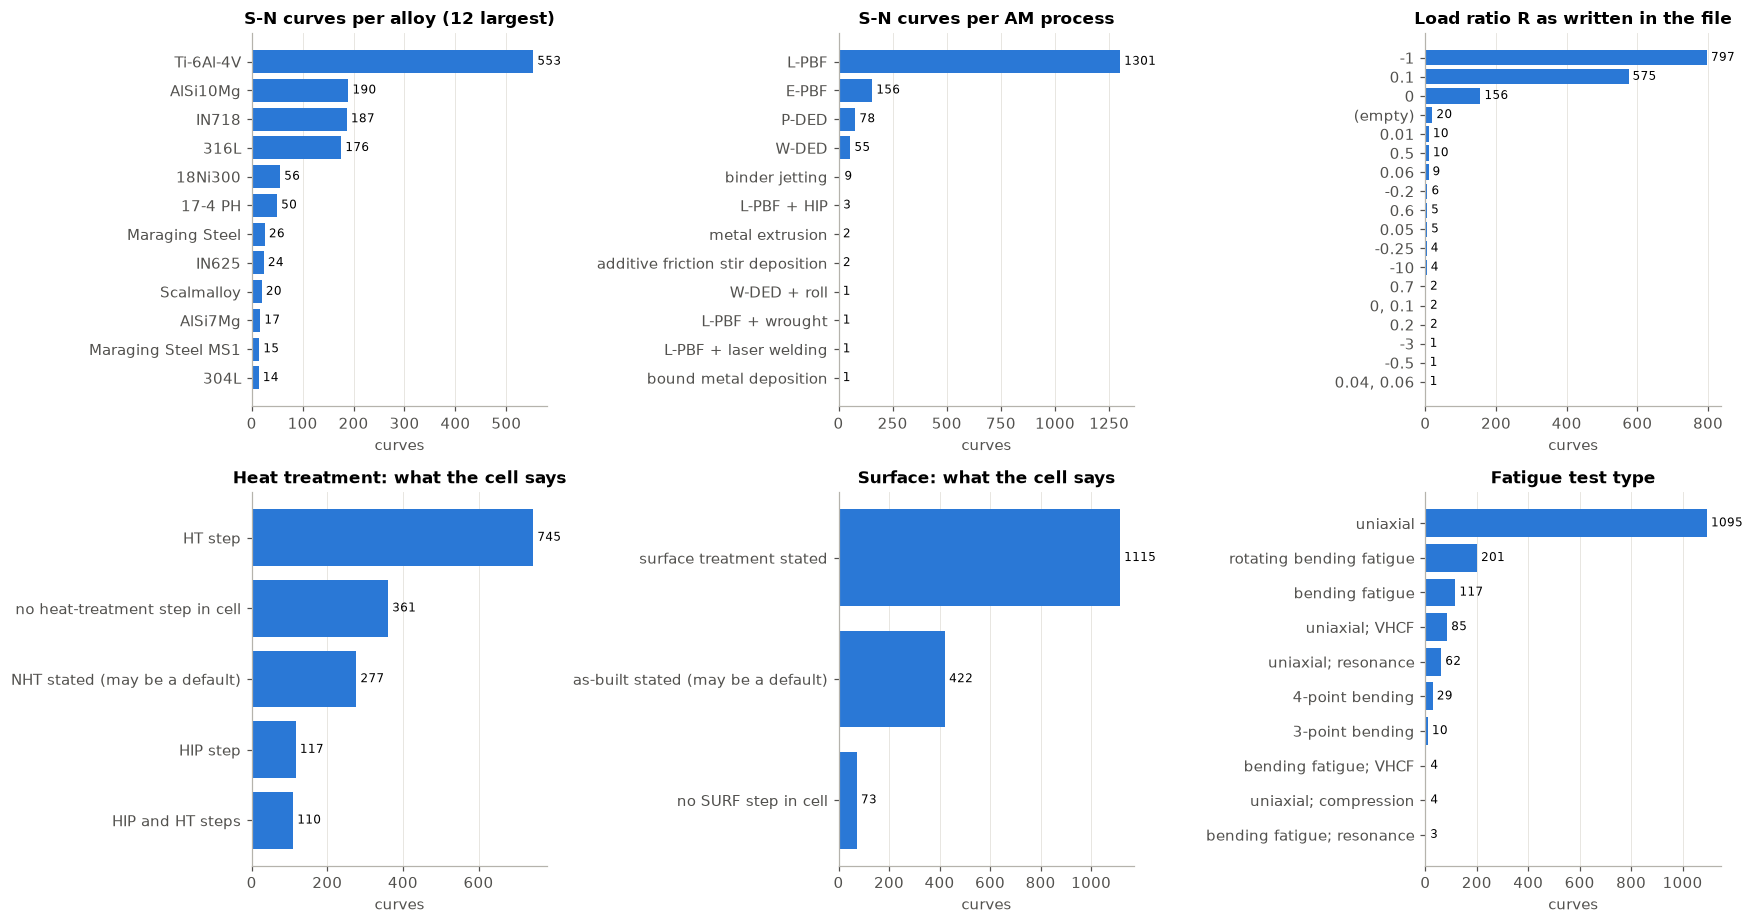

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))

top_alloys = alloy_table.sort_values("curves").tail(12)
axes[0, 0].barh(top_alloys.index, top_alloys["curves"], color=PALETTE[0])
axes[0, 0].set(title="S-N curves per alloy (12 largest)", xlabel="curves")

process_counts = param_sn["am_process"].value_counts()[::-1]
axes[0, 1].barh(process_counts.index, process_counts.values, color=PALETTE[0])
axes[0, 1].set(title="S-N curves per AM process", xlabel="curves")

r_counts = param_sn["R"].astype("object").where(param_sn["R"].notna(), "(empty)").astype(str).value_counts()[::-1]
axes[0, 2].barh(r_counts.index, r_counts.values, color=PALETTE[0])
axes[0, 2].set(title="Load ratio R as written in the file", xlabel="curves")

ht_plot = ht_evidence["curves"][::-1]
axes[1, 0].barh(ht_plot.index, ht_plot.values, color=PALETTE[0])
axes[1, 0].set(title="Heat treatment: what the cell says", xlabel="curves")

surf_plot = surf_evidence["curves"][::-1]
axes[1, 1].barh(surf_plot.index, surf_plot.values, color=PALETTE[0])
axes[1, 1].set(title="Surface: what the cell says", xlabel="curves")

test_counts = param_sn["test_type"].value_counts()[::-1]
axes[1, 2].barh(test_counts.index, test_counts.values, color=PALETTE[0])
axes[1, 2].set(title="Fatigue test type", xlabel="curves")

for ax in axes.ravel():
    ax.grid(axis="y", visible=False)
    for patch in ax.patches:
        ax.text(patch.get_width(), patch.get_y() + patch.get_height() / 2, f" {int(patch.get_width())}", va="center", fontsize=8)
fig.tight_layout()
save_figure(fig, FIG_DIR / "01_category_distributions.png")
plt.show()

*Note:* Ti-6Al-4V and L-PBF dominate the data. Most curves carry the default values, so "25 °C" or "Kt = 1" means "room temperature / smooth, or not reported".

## 10. Missing values

Plot the percentage of empty cells per metadata column for the S-N curves. Columns with a default value show 0% missing because the default was filled in.

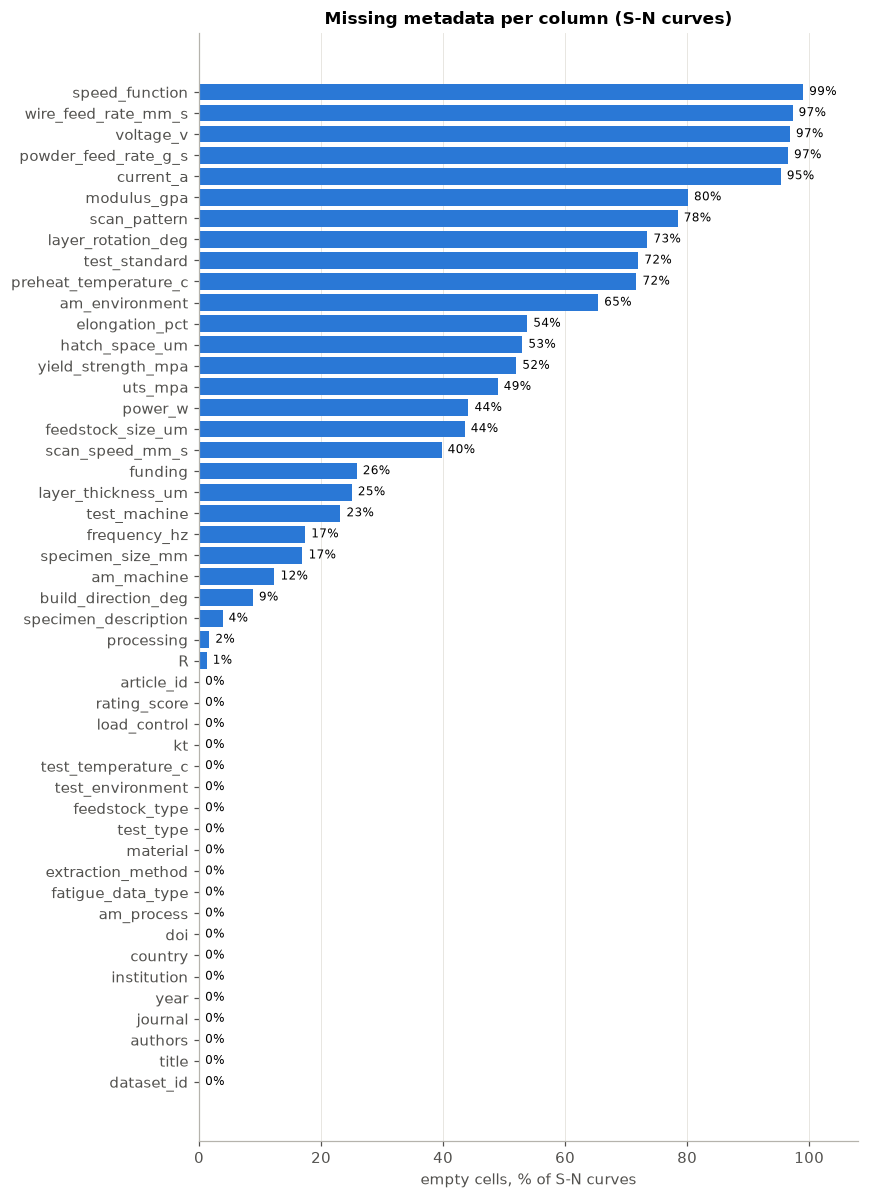

Curves with every lean-feature source column filled: 97.3%
Curves with UTS filled: 51.1% | curves with all four static properties: 17.2%
Curves with laser power, scan speed, hatch and layer thickness all filled: 41.4%


In [18]:
missing = (100 * param_sn.drop(columns=["alloy_family"]).isna().mean()).sort_values()
missing.round(2).rename("missing_pct").to_csv(AUDIT_DIR / "parameter_missingness_sn_curves.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(missing.index, missing.values, color=PALETTE[0])
for y, value in enumerate(missing.values):
    ax.text(value + 1, y, f"{value:.0f}%", va="center", fontsize=8)
ax.set(xlabel="empty cells, % of S-N curves", title="Missing metadata per column (S-N curves)", xlim=(0, 108))
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_figure(fig, FIG_DIR / "01_missingness.png")
plt.show()

lean = ["material", "am_process", "processing", "test_type", "R", "test_temperature_c"]
print("Curves with every lean-feature source column filled:", f"{100 * param_sn[lean].notna().all(axis=1).mean():.1f}%")
print("Curves with UTS filled:", f"{100 * param_sn['uts_mpa'].notna().mean():.1f}%",
      "| curves with all four static properties:", f"{100 * param_sn[['uts_mpa', 'yield_strength_mpa', 'modulus_gpa', 'elongation_pct']].notna().all(axis=1).mean():.1f}%")
process_columns = ["power_w", "scan_speed_mm_s", "hatch_space_um", "layer_thickness_um"]
print("Curves with laser power, scan speed, hatch and layer thickness all filled:", f"{100 * param_sn[process_columns].notna().all(axis=1).mean():.1f}%")

*Note:* the lean feature columns are almost complete, but UTS and process parameters are missing for about half of the curves, so static properties are used only in a separate feature tier.

## 11. Exploratory plots of the fatigue data

### 11.1 Fatigue life and stress amplitude

Plot log10(N) for failures and run-outs separately, and the distribution of stress amplitude.

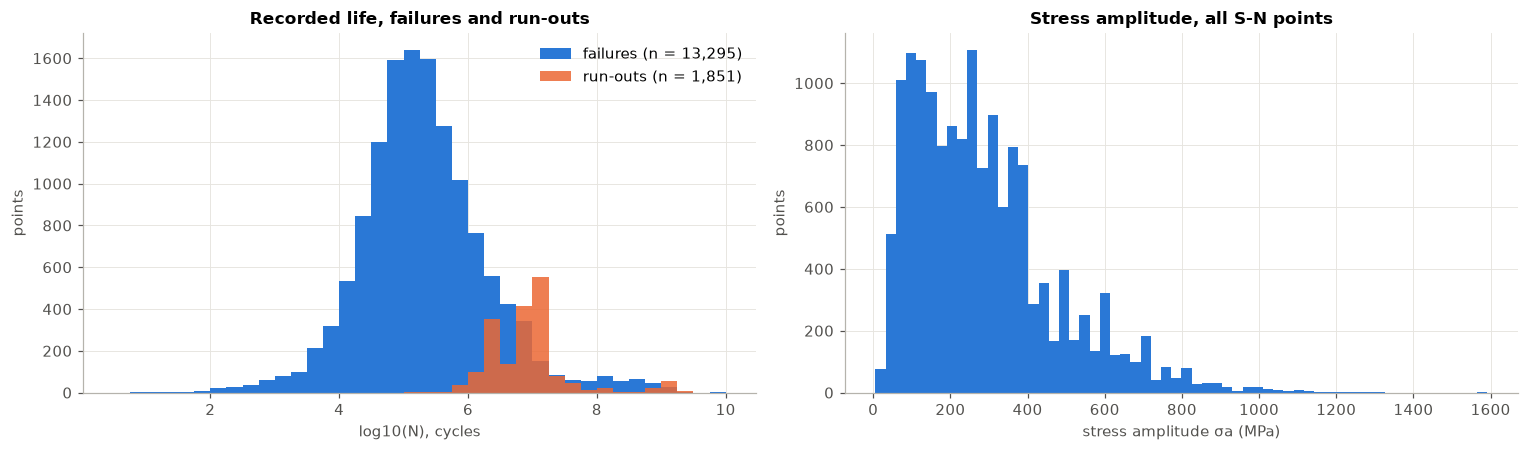

Failures by fatigue regime:
N
LCF (N < 1e4)        6.6%
HCF (1e4 to 1e7)    88.7%
VHCF (N > 1e7)       4.7%


In [19]:
log_N = np.log10(sn["N"])
bins = np.arange(0.5, 10.25, 0.25)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].hist(log_N[sn["runout"] == 0], bins=bins, color=PALETTE[0], label=f"failures (n = {(sn['runout'] == 0).sum():,})")
axes[0].hist(log_N[sn["runout"] == 1], bins=bins, color=PALETTE[1], alpha=0.85, label=f"run-outs (n = {(sn['runout'] == 1).sum():,})")
axes[0].set(title="Recorded life, failures and run-outs", xlabel="log10(N), cycles", ylabel="points")
axes[0].legend()

axes[1].hist(sn["stress_amplitude"], bins=60, color=PALETTE[0])
axes[1].set(title="Stress amplitude, all S-N points", xlabel="stress amplitude σa (MPa)", ylabel="points")
fig.tight_layout()
save_figure(fig, FIG_DIR / "01_life_and_stress_histograms.png")
plt.show()

regimes = pd.cut(sn.loc[sn["runout"] == 0, "N"], bins=[0, 1e4, 1e7, np.inf], labels=["LCF (N < 1e4)", "HCF (1e4 to 1e7)", "VHCF (N > 1e7)"])
print("Failures by fatigue regime:")
print((100 * regimes.value_counts(normalize=True).sort_index()).round(1).astype(str).add("%").to_string())

### 11.2 S-N scatter for the four largest alloys

Plot all failure points of each alloy in grey, with the three largest articles highlighted in colour.

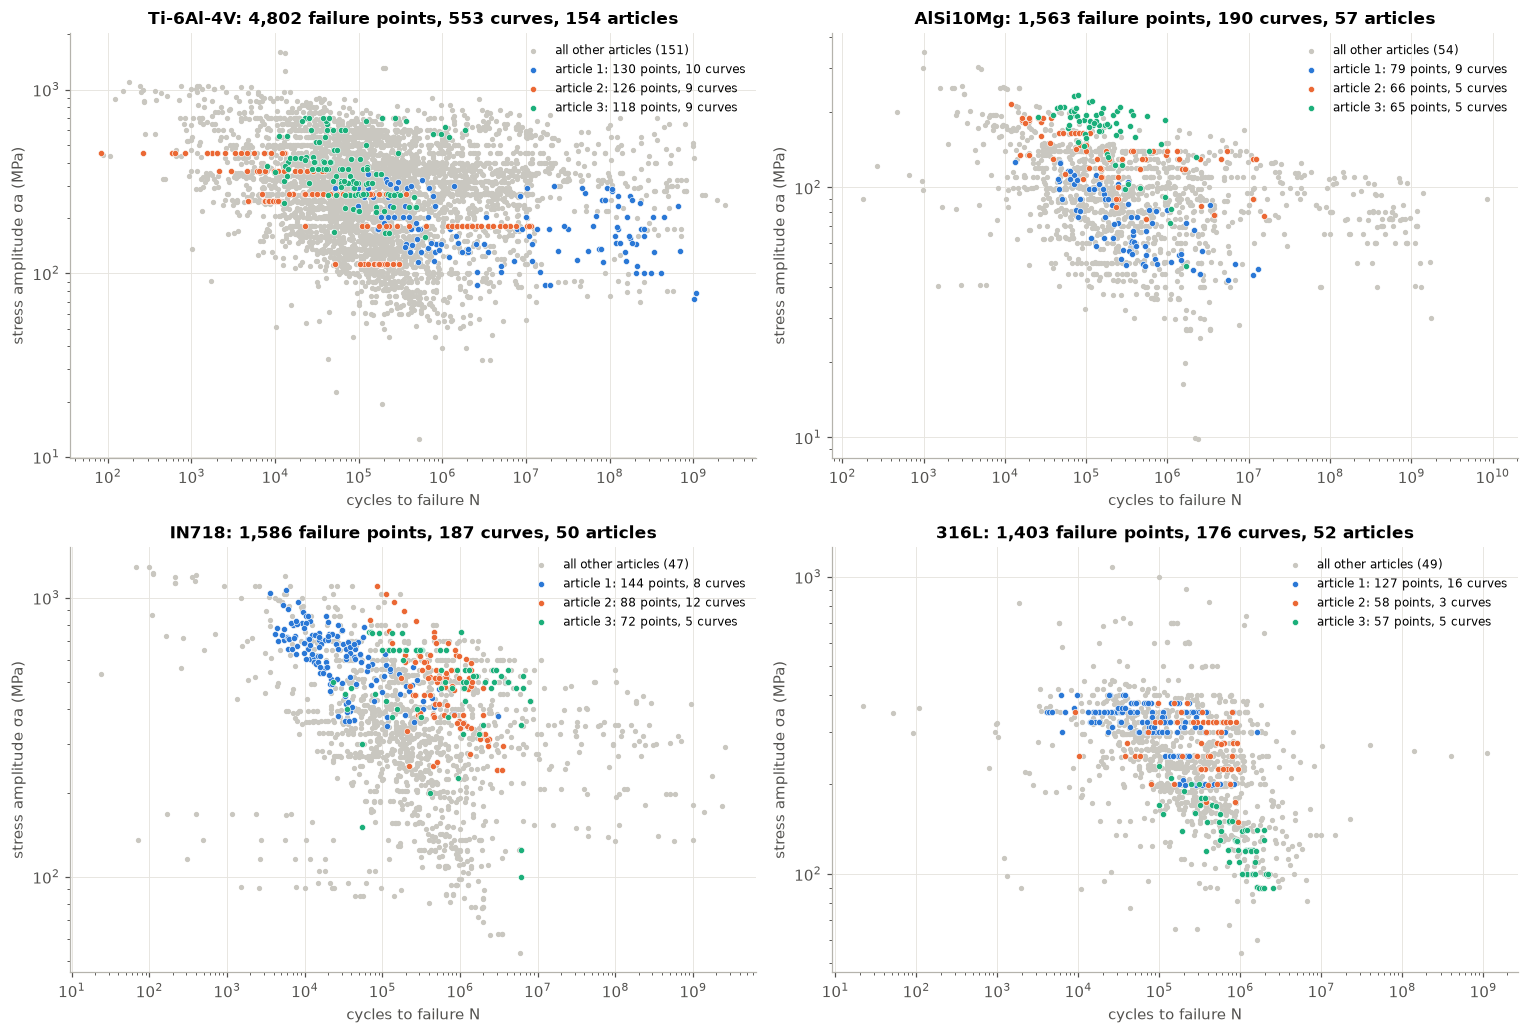

In [20]:
failures = joined[joined["runout"] == 0]
main_alloys = alloy_table.index[:4].tolist()

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
for ax, alloy in zip(axes.ravel(), main_alloys):
    sub = failures[failures["material"].astype(str) == alloy]
    ax.scatter(sub["N"], sub["stress_amplitude"], s=6, color="#c9c7c0", label=f"all other articles ({sub['article_id'].nunique() - 3})", rasterized=True)
    biggest = sub["article_id"].value_counts().index[:3]
    for k, article in enumerate(biggest):
        one = sub[sub["article_id"] == article]
        ax.scatter(one["N"], one["stress_amplitude"], s=16, color=PALETTE[k], edgecolor="white", linewidth=0.4,
                   label=f"article {k + 1}: {len(one)} points, {one['dataset_id'].nunique()} curves")
    ax.set(xscale="log", yscale="log", xlabel="cycles to failure N", ylabel="stress amplitude σa (MPa)",
           title=f"{alloy}: {len(sub):,} failure points, {sub['dataset_id'].nunique()} curves, {sub['article_id'].nunique()} articles")
    ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
save_figure(fig, FIG_DIR / "01_sn_scatter_main_alloys.png")
plt.show()

*Note:* points from one article form compact bands, so a model can learn "which article" instead of "how the alloy behaves".

### 11.3 Scatter split by article, curve and point

Fit one Basquin line log10(N) = A + B·log10(σa) per alloy and split the remaining scatter into article, curve and within-curve parts (descriptive only).

In [21]:
from evaluation_utils import variance_components

rows = []
for alloy in main_alloys:
    sub = failures[failures["material"].astype(str) == alloy].copy()
    slope, intercept = np.polyfit(np.log10(sub["stress_amplitude"]), np.log10(sub["N"]), 1)
    sub["residual"] = np.log10(sub["N"]) - (intercept + slope * np.log10(sub["stress_amplitude"]))
    parts = variance_components(sub, "residual", article="article_id", curve="dataset_id")
    rows.append({"alloy": alloy, "Basquin slope B": round(slope, 2), "residual std (log10 N)": round(sub["residual"].std(), 3),
                 "between articles %": round(100 * parts["share_between_articles"], 1),
                 "between curves within article %": round(100 * parts["share_between_curves_within_article"], 1),
                 "within curve %": round(100 * parts["share_within_curve"], 1)})
scatter_split = pd.DataFrame(rows)
scatter_split.to_csv(AUDIT_DIR / "scatter_decomposition_main_alloys.csv", index=False)
scatter_split

,alloy,Basquin slope B,residual std (log10 N),between articles %,between curves within article %,within curve %
0,Ti-6Al-4V,-0.81,1.037,51.1,12.3,36.7
1,AlSi10Mg,-1.92,1.026,55.9,10.6,33.5
2,IN718,-1.43,0.993,64.6,6.9,28.5
3,316L,-1.78,0.631,41.5,17.9,40.7


*Note:* a large share of the scatter is an article-level offset, which a randomly split model can pick up from neighbouring points.

### 11.4 Articles per alloy

Count the source articles behind each alloy. Alloys with at least 15 articles are reported separately in notebook 04.

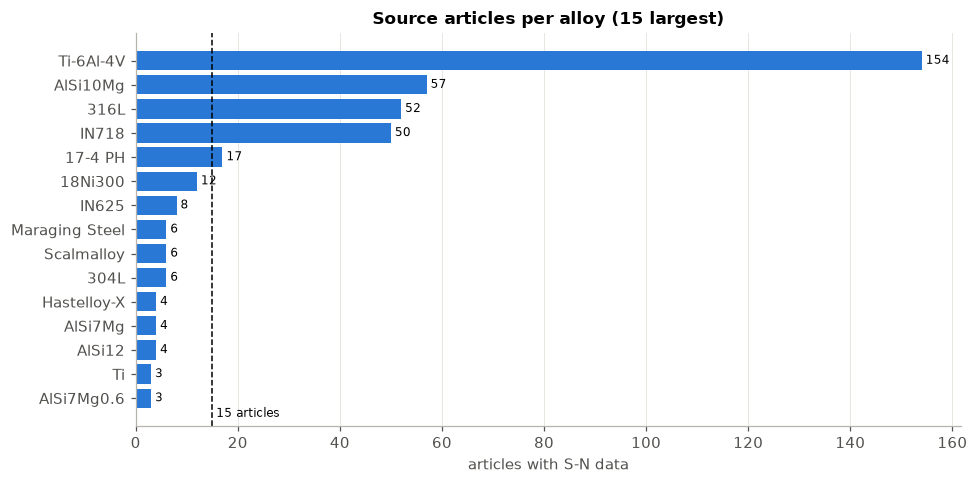

Alloys with at least 15 articles: Ti-6Al-4V (154), AlSi10Mg (57), 316L (52), IN718 (50), 17-4 PH (17)
Alloys with fewer than 15 articles: 91 of 96; they hold 26.6% of the S-N points


In [22]:
articles_per_alloy = alloy_table["articles"]
fig, ax = plt.subplots(figsize=(9, 4.5))
top = articles_per_alloy.sort_values(ascending=False).head(15)[::-1]
ax.barh(top.index, top.values, color=PALETTE[0])
for y, value in enumerate(top.values):
    ax.text(value, y, f" {value}", va="center", fontsize=8)
ax.axvline(15, color="black", lw=1, ls="--")
ax.text(15, -0.9, " 15 articles", fontsize=8, va="bottom")
ax.set(title="Source articles per alloy (15 largest)", xlabel="articles with S-N data")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_figure(fig, FIG_DIR / "01_articles_per_alloy.png")
plt.show()

print("Alloys with at least 15 articles:", ", ".join(f"{a} ({n})" for a, n in articles_per_alloy[articles_per_alloy >= 15].sort_values(ascending=False).items()))
print(f"Alloys with fewer than 15 articles: {(articles_per_alloy < 15).sum()} of {len(articles_per_alloy)}; they hold {100 * alloy_table.loc[articles_per_alloy < 15, 'points'].sum() / alloy_table['points'].sum():.1f}% of the S-N points")

## 12. Data-quality checks

### 12.1 Duplicates

Count exact duplicates of (stress, life) inside curves, inside articles and across articles. Also search for near-duplicate curves from different articles of the same alloy: a point matches within 0.01 in log10 stress and 0.02 in log10 life, and a pair is flagged when at least 4 points and 80% of the smaller curve match.

In [23]:
key = ["stress_amplitude", "N"]
dup_rows = joined[joined.duplicated(subset=key, keep=False)]
groups = dup_rows.groupby(key).agg(rows=("dataset_id", "size"), curves=("dataset_id", "nunique"), articles=("article_id", "nunique"))
duplicate_summary = {
    "fully_duplicated_SN_rows_beyond_first": int(sn.duplicated().sum()),
    "rows_sharing_exact_stress_and_life_with_another_row": int(len(dup_rows)),
    "duplicate_groups_total": int(len(groups)),
    "groups_within_one_curve": int((groups["curves"] == 1).sum()),
    "groups_across_curves_same_article": int(((groups["curves"] > 1) & (groups["articles"] == 1)).sum()),
    "groups_across_articles": int((groups["articles"] > 1).sum()),
}

# Near-duplicate curves across articles (same alloy, points coinciding within ~2% in stress and ~5% in life).
near_duplicates = du.find_near_duplicate_curves(joined)
info = param.set_index("dataset_id")[["year"]]
near_duplicates = near_duplicates.join(info.add_suffix("_a"), on="dataset_id_a").join(info.add_suffix("_b"), on="dataset_id_b")
near_curves = set(near_duplicates["dataset_id_a"]) | set(near_duplicates["dataset_id_b"])
near_articles = set(near_duplicates["article_id_a"]) | set(near_duplicates["article_id_b"])
near_duplicates.to_csv(AUDIT_DIR / "near_duplicate_curves_across_articles.csv", index=False, encoding="utf-8-sig")
duplicate_summary["near_duplicate_curve_pairs_across_articles"] = int(len(near_duplicates))
duplicate_summary["curves_in_a_near_duplicate_pair"] = int(len(near_curves))
duplicate_summary["articles_in_a_near_duplicate_pair"] = int(len(near_articles))
duplicate_summary["points_in_near_duplicate_curves"] = int(joined["dataset_id"].isin(near_curves).sum())

# For information: the same search inside single articles (the same data stored under two dataset ids).
within_article = du.find_near_duplicate_curves(joined, across_articles=False)
duplicate_summary["near_identical_curve_pairs_inside_one_article"] = int(len(within_article))
duplicate_summary["curves_in_such_within_article_pairs"] = int(len(set(within_article["dataset_id_a"]) | set(within_article["dataset_id_b"])))
du.save_json(duplicate_summary, AUDIT_DIR / "duplicate_summary.json")

for name, value in duplicate_summary.items():
    print(f"{name:65s}: {value}")
with pd.option_context("display.max_rows", 12):
    display(near_duplicates[["dataset_id_a", "dataset_id_b", "alloy", "shared_points", "smaller_curve_points", "article_id_a", "year_a", "article_id_b", "year_b"]])

# One example pair, side by side: the same specimens printed in two publications.
example = near_duplicates.sort_values("shared_points", ascending=False).iloc[0]
side_by_side = pd.concat(
    [sn[sn["dataset_id"] == example[f"dataset_id_{s}"]].sort_values(["stress_amplitude", "N"]).reset_index(drop=True)[["stress_amplitude", "N"]].round(1).add_suffix(f" (curve {example[f'dataset_id_{s}']})")
     for s in ("a", "b")], axis=1)
print("Example pair:", example["article_id_a"], "and", example["article_id_b"])
display(side_by_side)

fully_duplicated_SN_rows_beyond_first                            : 38
rows_sharing_exact_stress_and_life_with_another_row              : 62
duplicate_groups_total                                           : 23
groups_within_one_curve                                          : 22
groups_across_curves_same_article                                : 1
groups_across_articles                                           : 0
near_duplicate_curve_pairs_across_articles                       : 85
curves_in_a_near_duplicate_pair                                  : 133
articles_in_a_near_duplicate_pair                                : 74
points_in_near_duplicate_curves                                  : 1473
near_identical_curve_pairs_inside_one_article                    : 10
curves_in_such_within_article_pairs                              : 19


,dataset_id_a,dataset_id_b,alloy,shared_points,smaller_curve_points,article_id_a,year_a,article_id_b,year_b
0,3,1019,Ti-6Al-4V,8,9,10.1007/978-3-030-05861-6_36,2019,10.1016/j.msea.2022.142747,2022
1,6,178,316L,11,11,10.1007/978-3-030-05861-6_36,2019,10.1016/j.addma.2021.102570,2022
2,6,384,316L,11,11,10.1007/978-3-030-05861-6_36,2019,10.1016/j.ijfatigue.2019.01.013,2019
3,7,181,316L,10,10,10.1007/978-3-030-05861-6_36,2019,10.1016/j.addma.2021.102570,2022
4,7,385,316L,10,10,10.1007/978-3-030-05861-6_36,2019,10.1016/j.ijfatigue.2019.01.013,2019
...,...,...,...,...,...,...,...,...,...
80,1253,1273,18Ni300,6,6,10.1111/ffe.12395,2016,10.1111/ffe.12917,2019
81,1412,1597,AlSi10Mg,4,4,10.3390/ma11010017,2018,10.3390/met8100825,2018
82,1565,1589,ER2594 steel,12,12,10.3390/met11121965,2021,10.3390/met12091548,2022
83,1566,1587,ER2594 steel,12,12,10.3390/met11121965,2021,10.3390/met12091548,2022


Example pair: 10.1016/j.ijfatigue.2018.12.024 and 10.1016/j.prostr.2017.11.064


,stress_amplitude (curve 383),N (curve 383),stress_amplitude (curve 1121),N (curve 1121)
0,188.7,9917285.6,189.1,9968370.1
1,197.9,7800384.6,197.7,7831023.6
2,198.0,9963499.1,198.0,9888959.1
3,198.0,9963020.7,206.8,3934126.5
4,198.1,9998371.1,206.9,3275547.1
5,206.8,3851574.3,206.9,8833700.1
6,207.0,3225957.7,224.7,180984.7
7,207.0,8853578.6,224.7,335330.5
8,224.9,1171753.1,224.7,1182443.0
9,224.9,181782.0,224.9,962494.5


### 12.2 Physical plausibility

Check for very short lives (N < 10), stresses above the reported UTS, and curves where life increases with stress.

In [24]:
print("Rows with N < 10 cycles:")
display(joined.loc[joined["N"] < 10, ["dataset_id", "material", "stress_amplitude", "N", "runout", "test_type", "load_control"]])

r_value, r_kind = du.single_value_or_nan(joined["R"])
sigma_max = 2 * joined["stress_amplitude"] / (1 - r_value)
has_uts = joined["uts_mpa"].notna()
print(f"Points with UTS reported: {int(has_uts.sum()):,}")
print(f"  stress amplitude above UTS : {int((joined['stress_amplitude'] > joined['uts_mpa']).sum()):,} points in {joined.loc[joined['stress_amplitude'] > joined['uts_mpa'], 'dataset_id'].nunique()} curves")
print(f"  maximum stress above UTS   : {int((sigma_max > joined['uts_mpa']).sum()):,} points in {joined.loc[sigma_max > joined['uts_mpa'], 'dataset_id'].nunique()} curves (uses R; bending and notched tests can exceed UTS nominally)")

# Curves in which life rises with stress (rank correlation between stress and life, failures only, >= 5 points).
def stress_life_rank_correlation(group):
    if len(group) < 5 or group["stress_amplitude"].nunique() < 3:
        return np.nan
    return group["stress_amplitude"].rank().corr(group["N"].rank())
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    rho = failures.groupby("dataset_id")[["stress_amplitude", "N"]].apply(stress_life_rank_correlation).dropna()
print(f"\nCurves with at least 5 failures and 3 stress levels: {len(rho):,}")
print(f"  median rank correlation between stress and life: {rho.median():.2f}")
print(f"  curves with a positive correlation (life rises with stress): {(rho > 0).sum()} ({100 * (rho > 0).mean():.1f}%)")

plausibility = {
    "rows_N_lt_10": int((joined["N"] < 10).sum()),
    "points_sa_above_uts": int((joined["stress_amplitude"] > joined["uts_mpa"]).sum()),
    "points_sigma_max_above_uts": int((sigma_max > joined["uts_mpa"]).sum()),
    "curves_checked_for_monotonic_trend": int(len(rho)),
    "curves_life_rises_with_stress": int((rho > 0).sum()),
    "R_cell_kinds_points": {k: int(v) for k, v in r_kind.value_counts().items()},
}
du.save_json(plausibility, AUDIT_DIR / "plausibility_checks.json")

Rows with N < 10 cycles:


,dataset_id,material,stress_amplitude,N,runout,test_type,load_control
7350,758,Ti,324.508578,9.710731,0,uniaxial,force
13696,1426,WE43,203.478923,9.964550,0,uniaxial; compression,force


Points with UTS reported: 8,088
  stress amplitude above UTS : 23 points in 12 curves
  maximum stress above UTS   : 222 points in 47 curves (uses R; bending and notched tests can exceed UTS nominally)



Curves with at least 5 failures and 3 stress levels: 1,263
  median rank correlation between stress and life: -0.91
  curves with a positive correlation (life rises with stress): 30 (2.4%)


*Note:* no exact duplicates link two articles, but the near-duplicate pairs show that some test series were published more than once. Flagged points are reported, not removed.

## 13. Confirmed columns

Save the key column names and their original workbook headers to `results/audit/confirmed_columns.json`. Notebook 02 reads this file.

In [25]:
reverse = {(sheet, new): original for sheet, mapping in column_maps.items() for original, new in mapping.items()}
def header(sheet, name):
    return reverse[(sheet, name)]

confirmed = {
    "workbook": "data/raw/FatigueData-AM2022.xlsx",
    "sheets": sheet_names,
    "parameter_sheet_header_row_index": 1,
    "columns": {
        "dataset_index": {"sheet": "S-N and parameter", "workbook_header": header("S-N", "dataset_id"), "project_name": "dataset_id"},
        "stress_amplitude": {"sheet": "S-N", "workbook_header": header("S-N", "stress_amplitude"), "project_name": "stress_amplitude", "unit": "MPa"},
        "cycles": {"sheet": "S-N", "workbook_header": header("S-N", "N"), "project_name": "N", "unit": "cycles"},
        "runout_flag": {"sheet": "S-N", "workbook_header": header("S-N", "runout"), "project_name": "runout",
                        "coding": "1 = run-out (test stopped before failure), 0 = failure", "coding_confirmed_from_data": bool(runout_confirmed)},
        "article_identifier": {"sheet": "parameter", "workbook_header": header("parameter", "doi"), "project_name": "doi -> article_id",
                               "fallback": header("parameter", "title"), "json_needed": False},
        "alloy": {"sheet": "parameter", "workbook_header": header("parameter", "material"), "project_name": "material"},
        "am_process": {"sheet": "parameter", "workbook_header": header("parameter", "am_process"), "project_name": "am_process"},
        "load_ratio": {"sheet": "parameter", "workbook_header": header("parameter", "R"), "project_name": "R",
                       "note": "stored as text; a few cells are empty or hold two values (bounds)"},
        "surface_and_heat_treatment": {"sheet": "parameter", "workbook_header": header("parameter", "processing"), "project_name": "processing",
                                       "note": "one free-text cell with HT / HIP / NHT / SURF steps separated by ';'"},
        "test_type": {"sheet": "parameter", "workbook_header": header("parameter", "test_type"), "project_name": "test_type"},
        "test_temperature": {"sheet": "parameter", "workbook_header": header("parameter", "test_temperature_c"), "project_name": "test_temperature_c",
                             "unit": "degree Celsius", "note": "never empty; 25 is the documented default for unreported"},
    },
    "counts_from_file": {"sn_points": int(len(sn)), "sn_curves": int(sn["dataset_id"].nunique()), "sn_articles": int(param_sn["article_id"].nunique()),
                         "runout_points": int(sn_checks["runout_count"])},
}
du.save_json(confirmed, AUDIT_DIR / "confirmed_columns.json")
confirmed_table = pd.DataFrame(confirmed["columns"]).T[["sheet", "workbook_header", "project_name"]]
confirmed_table["workbook_header"] = confirmed_table["workbook_header"].str.replace("\r\n", " ⏎ ").str.replace("\n", " ⏎ ")
confirmed_table

,sheet,workbook_header,project_name
dataset_index,S-N and parameter,dataset id,dataset_id
stress_amplitude,S-N,stress amplitude ⏎ σa (MPa),stress_amplitude
cycles,S-N,life ⏎ N (cycle),N
runout_flag,S-N,runout,runout
article_identifier,parameter,DOI,doi -> article_id
alloy,parameter,name of the material,material
am_process,parameter,types of AM,am_process
load_ratio,parameter,load ratio,R
surface_and_heat_treatment,parameter,processing sequence and parameters,processing
test_type,parameter,types of fatigue tests,test_type


## 14. Summary

- The workbook is the original Figshare version 2 file, and the reported headline counts are reproduced.
- The run-out coding is confirmed (1 = run-out, 0 = failure).
- The data are nested (points within curves within articles), and much of the scatter is an article-level offset.
- Ti-6Al-4V and L-PBF dominate, and many metadata values are defaults.
- Some test series appear in more than one article (near-duplicate curves).
- Notebook 02 uses these results to filter the data and build the modelling dataset.